In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set()


In [5]:
df = pd.read_csv("Console_Data.csv")
df.head()


,Console Name,Type,Company,Gen,Gen Years,Released Year,Generation,Discontinuation Year,Units sold (million),Remarks,Link to gif
0,Magnavox Odyssey,Home,Magnavox,1st Gen,1972-1978,1972,1,1975,0.35,The Magnavox Odyssey is the first commercial ...,https://s12.gifyu.com/images/SVLO3.gif
1,Home Pong,Home,Atari,1st Gen,1972-1978,1975,1,1978,0.15,Atari's Home Pong was a dedicated console that...,https://s12.gifyu.com/images/SVz99.gif
2,Atari 2600,Home,Atari,2nd Gen,1978-1982,1977,2,1992,30.00,Atari2600 is often credited with popularizing ...,https://s12.gifyu.com/images/SVz3U.gif
3,Magnavox Odyssey 2,Home,Magnavox,2nd Gen,1978-1982,1978,2,1984,2.00,The Odyssey² featured a built-in keyboard for ...,https://s12.gifyu.com/images/SVz70.gif
4,Intellivision,Home,Mattel,2nd Gen,1978-1982,1979,2,1990,3.00,The Intellivision boasted superior graphics an...,https://s12.gifyu.com/images/SVLBF.gif


In [4]:
# Check Missing Values
print(df.isna())
print(df.isna().sum())


    Console Name   Type  Company    Gen  Gen Years  Released Year  Generation  \
0          False  False    False  False      False          False       False   
1          False  False    False  False      False          False       False   
2          False  False    False  False      False          False       False   
3          False  False    False  False      False          False       False   
4          False  False    False  False      False          False       False   
5          False  False    False  False      False          False       False   
6          False  False    False  False      False          False       False   
7          False  False    False  False      False          False       False   
8          False  False    False  False      False          False       False   
9          False  False    False  False      False          False       False   
10         False  False    False  False      False          False       False   
11         False  False    F

In [8]:
# Number of Rows and Columns
print("Shape (rows, columns): ", df.shape, "\n")
print("Number of rows: ", df.shape[0])
print("Number of columns: ", df.shape[1])


Shape (rows, columns):  (26, 11) 

Number of rows:  26
Number of columns:  11


In [9]:
df.dtypes


Console Name             object
Type                     object
Company                  object
Gen                      object
Gen Years                object
Released Year             int64
Generation                int64
Discontinuation Year     object
Units sold (million)    float64
Remarks                  object
Link to gif              object
dtype: object

In [12]:
# to make sure of the data types
df['Units sold (million)'] = pd.to_numeric(df['Units sold (million)'], errors='coerce')
df['Released Year'] = pd.to_numeric(df['Released Year'], errors='coerce')
df['Discontinuation Year'] = pd.to_numeric(df['Discontinuation Year'], errors='coerce')

df.dtypes


Console Name             object
Type                     object
Company                  object
Gen                      object
Gen Years                object
Released Year             int64
Generation                int64
Discontinuation Year    float64
Units sold (million)    float64
Remarks                  object
Link to gif              object
dtype: object

In [11]:
df.describe(include='all')

,Console Name,Type,Company,Gen,Gen Years,Released Year,Generation,Discontinuation Year,Units sold (million),Remarks,Link to gif
count,26,26,26,26,26,26.000000,26.000000,22.000000,26.000000,26,26
unique,26,1,7,9,9,NaN,NaN,NaN,NaN,26,26
top,Magnavox Odyssey,Home,Nintendo,6th Gen,1998-2005,NaN,NaN,NaN,NaN,The Magnavox Odyssey is the first commercial ...,https://s12.gifyu.com/images/SVLO3.gif
freq,1,26,7,4,4,NaN,NaN,NaN,NaN,1,1
mean,NaN,NaN,NaN,NaN,NaN,1996.384615,5.230769,2000.681818,47.326923,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,14.612534,2.550415,13.050767,45.542229,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,1972.000000,1.000000,1975.000000,0.150000,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,1983.750000,3.000000,1992.750000,10.000000,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,1997.000000,5.500000,2001.500000,31.500000,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,2006.000000,7.000000,2012.000000,78.500000,NaN,NaN


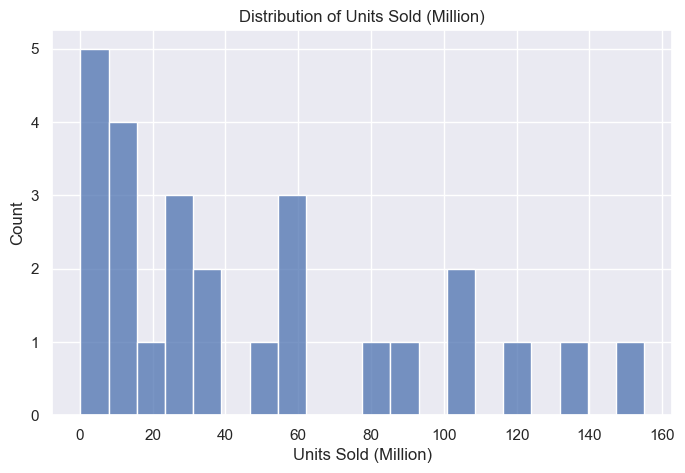

In [13]:
#  Distribution Units Sold by Million
plt.figure(figsize=(8,5))
sns.histplot(df['Units sold (million)'], bins=20)
plt.title("Distribution of Units Sold (Million)")
plt.xlabel("Units Sold (Million)")
plt.show()


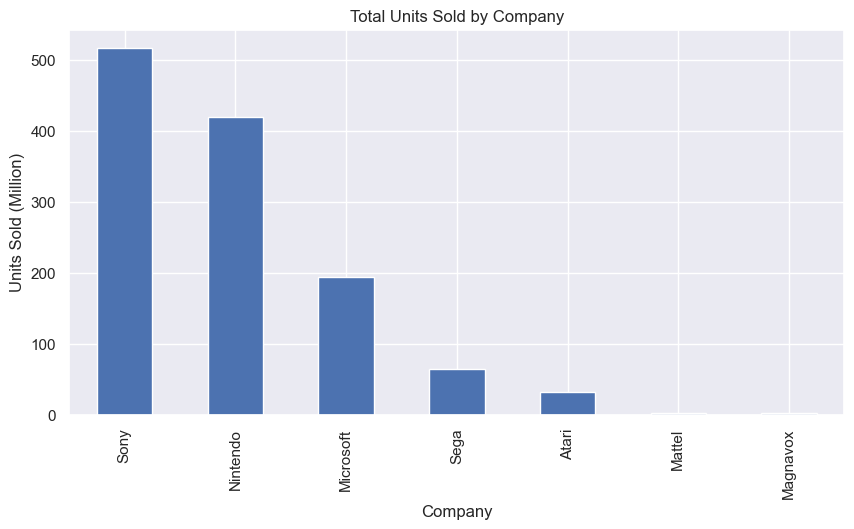

Company
Sony         516.00
Nintendo     419.00
Microsoft    194.00
Sega          64.00
Atari         32.15
Mattel         3.00
Magnavox       2.35
Name: Units sold (million), dtype: float64

In [15]:
# Units Sold by Company
company_sales = df.groupby('Company')['Units sold (million)'].sum().sort_values(ascending=False)

plt.figure(figsize=(10,5))
company_sales.plot(kind='bar')
plt.title("Total Units Sold by Company")
plt.ylabel("Units Sold (Million)")
plt.show()

company_sales


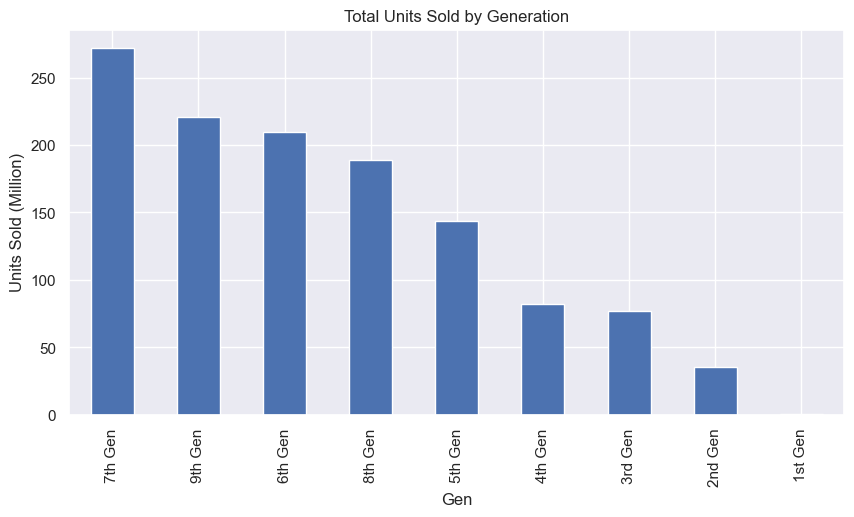

Gen
7th Gen    272.0
9th Gen    221.0
6th Gen    210.0
8th Gen    189.0
5th Gen    144.0
4th Gen     82.0
3rd Gen     77.0
2nd Gen     35.0
1st Gen      0.5
Name: Units sold (million), dtype: float64

In [16]:
gen_sales = df.groupby('Gen')['Units sold (million)'].sum().sort_values(ascending=False)

plt.figure(figsize=(10,5))
gen_sales.plot(kind='bar')
plt.title("Total Units Sold by Generation")
plt.ylabel("Units Sold (Million)")
plt.show()

gen_sales


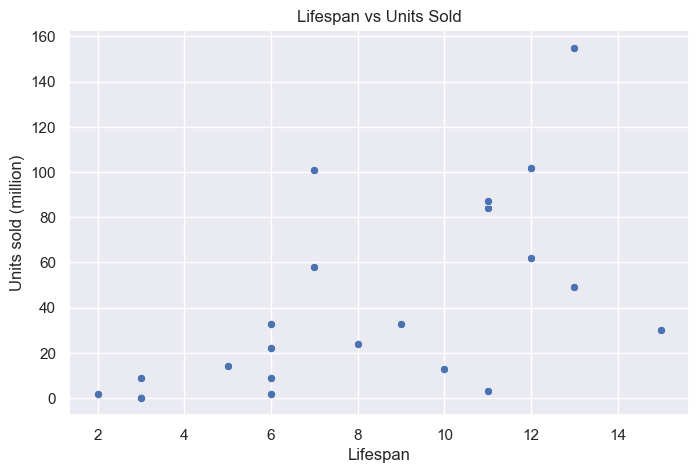

In [17]:
df['Lifespan'] = df['Discontinuation Year'] - df['Released Year']

plt.figure(figsize=(8,5))
sns.scatterplot(x='Lifespan', y='Units sold (million)', data=df)
plt.title("Lifespan vs Units Sold")
plt.show()


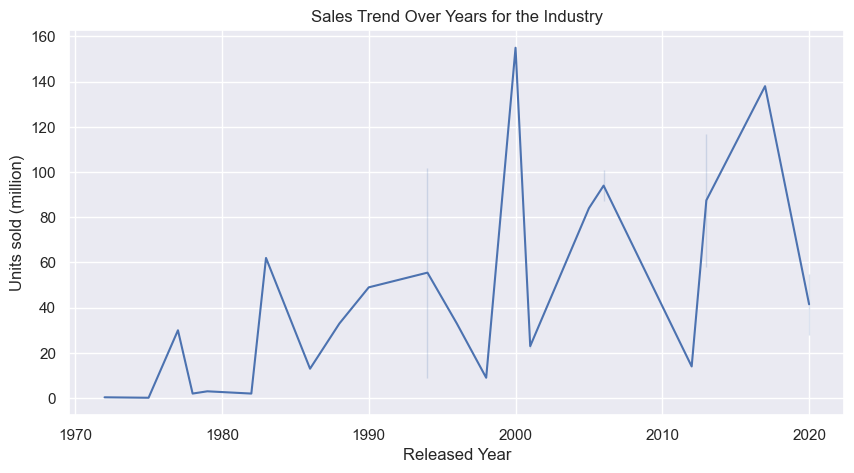

In [21]:
plt.figure(figsize=(10,5))
sns.lineplot(x='Released Year', y='Units sold (million)', data=df)
plt.title("Sales Trend Over Years for the Industry")
plt.show()


In [9]:
# Select only numeric columns
numeric_df = df.select_dtypes(include='number')

# Correlation matrix
correlation = numeric_df.corr()

print("Correlation Matrix:\n")
print(correlation)


Correlation Matrix:

                      Released Year  Generation  Units sold (million)
Released Year              1.000000    0.995698              0.523357
Generation                 0.995698    1.000000              0.543441
Units sold (million)       0.523357    0.543441              1.000000


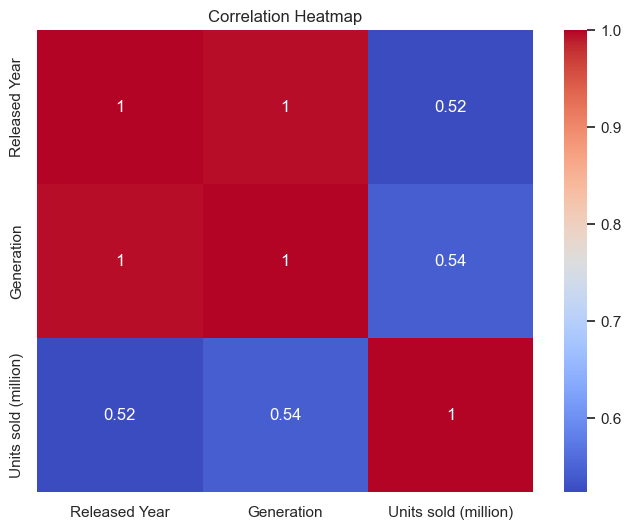

In [10]:

plt.figure(figsize=(8,6))
sns.heatmap(correlation, annot=True, cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()
